Dataset shape: (1800, 18)
   product_id        date category  opening_stock  units_received  units_sold  \
0        1001  2026-04-01    Dairy             27               0           6   
1        1001  2026-04-02    Dairy             30              12           5   
2        1001  2026-04-03    Dairy             38               0          14   
3        1001  2026-04-04    Dairy             49               0          11   
4        1001  2026-04-05    Dairy             19              13          12   

   unit_price  discount_pct  days_to_expiry  temperature_c  waste_units  \
0        32.0           0.0               1            4.1            0   
1        32.0           0.0               5            3.7            0   
2        32.0           0.0               2            4.6            0   
3        32.0           0.0               0            5.7            0   
4        32.0           0.0               0            3.0            0   

   stockout_flag  day_of_week  month


Demand Forecasting Results
--------------------------
MAE: 4.06
RMSE: 5.11
R2 Score: 0.698

Predictions saved to ml/outputs/demand_forecast_predictions.csv
Model saved to ml/models/demand_forecasting_model.pkl


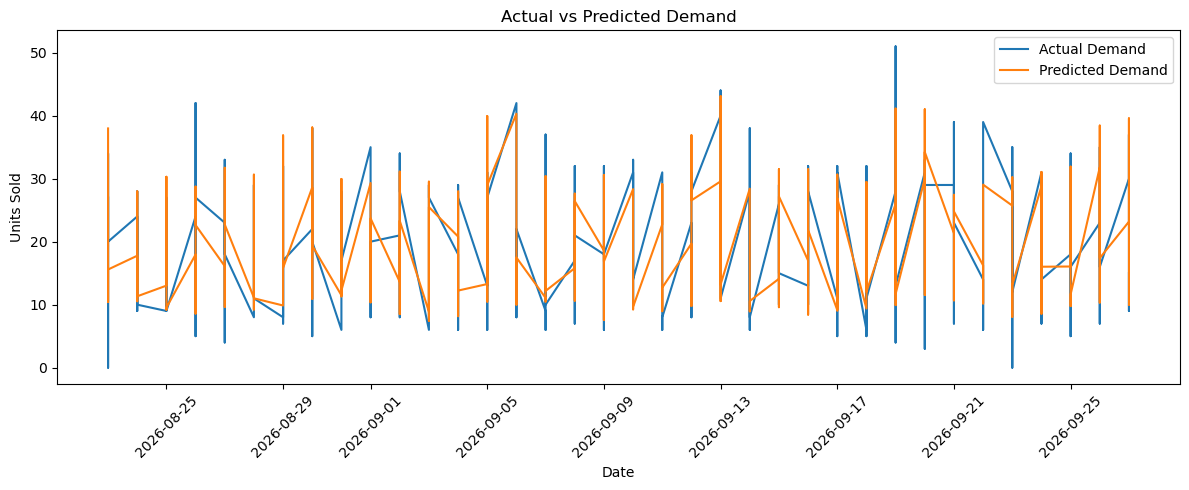


Feature Importance:
product_id_1006    0.209464
product_id_1002    0.155942
product_id_1008    0.134676
product_id_1003    0.125782
day_of_week        0.063334
product_id_1004    0.050929
rolling_mean_7     0.048627
product_id_1005    0.047966
lag_1              0.042608
day                0.041684
month              0.034884
lag_7              0.033196
product_id_1009    0.008120
product_id_1007    0.001097
product_id_1001    0.000872
product_id_1010    0.000818
year               0.000000
dtype: float64


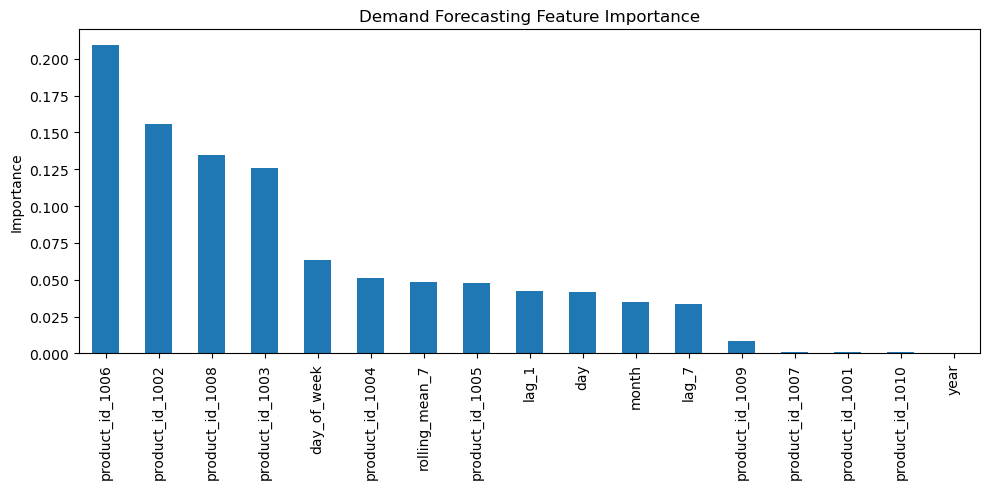


Sample Forecasts:
           date  units_sold  predicted_demand
1434 2026-08-23          27         37.977875
1435 2026-08-23          10         11.950976
1436 2026-08-23          22         28.150333
1437 2026-08-23          25         31.887673
1438 2026-08-23          14         20.854280
1439 2026-08-23          34         30.303200
1440 2026-08-23          18         17.900310
1441 2026-08-23           0         10.431000
1442 2026-08-23          20         15.582113
1443 2026-08-24          24         17.770875


In [1]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

data_path = r"..\data\processed\perishable_features.csv"

if not os.path.exists(data_path):
    data_path = r"ml\data\processed\perishable_features.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print(df.head())

df.columns = df.columns.str.strip()

if "date" not in df.columns or "units_sold" not in df.columns:
    raise ValueError("Dataset must contain 'date' and 'units_sold' columns.")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["units_sold"] = pd.to_numeric(df["units_sold"], errors="coerce")

df = df.dropna(subset=["date", "units_sold"])
df = df.sort_values("date").reset_index(drop=True)

df["day"] = df["date"].dt.day
df["month"] = df["date"].dt.month
df["day_of_week"] = df["date"].dt.dayofweek
df["year"] = df["date"].dt.year

df["lag_1"] = df["units_sold"].shift(1)
df["lag_7"] = df["units_sold"].shift(7)
df["rolling_mean_7"] = df["units_sold"].shift(1).rolling(7).mean()

df = df.dropna().reset_index(drop=True)

if len(df) < 10:
    raise ValueError("Not enough rows after creating lag features. Use a larger dataset.")

features = [
    "day",
    "month",
    "day_of_week",
    "year",
    "lag_1",
    "lag_7",
    "rolling_mean_7"
]

if "product_id" in df.columns:
    df["product_id"] = df["product_id"].astype(str)
    df = pd.get_dummies(df, columns=["product_id"], dtype=int)
    product_columns = [
        col for col in df.columns if col.startswith("product_id_")
    ]
    features.extend(product_columns)

X = df[features]
y = df["units_sold"]

split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    min_samples_leaf=2
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)
predictions = np.maximum(predictions, 0)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions) if len(y_test) > 1 else float("nan")

print("\nDemand Forecasting Results")
print("--------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 3))

results = df.iloc[split_index:][["date", "units_sold"]].copy()
results["predicted_demand"] = predictions

os.makedirs("ml/outputs", exist_ok=True)
os.makedirs("ml/models", exist_ok=True)

results.to_csv("ml/outputs/demand_forecast_predictions.csv", index=False)
joblib.dump(model, "ml/models/demand_forecasting_model.pkl")
joblib.dump(features, "ml/models/demand_forecasting_features.pkl")

print("\nPredictions saved to ml/outputs/demand_forecast_predictions.csv")
print("Model saved to ml/models/demand_forecasting_model.pkl")

plt.figure(figsize=(12, 5))
plt.plot(results["date"], results["units_sold"], label="Actual Demand")
plt.plot(results["date"], results["predicted_demand"], label="Predicted Demand")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.title("Actual vs Predicted Demand")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(ascending=False)

print("\nFeature Importance:")
print(importance)

importance.plot(kind="bar", figsize=(10, 5))
plt.title("Demand Forecasting Feature Importance")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

print("\nSample Forecasts:")
print(results.head(10))
